# 05 — Evaluation and Comparison

**Project 2.2 — Cross-Modal Retrieval: Mobile App Screens and Text Summaries**
Tess Santhosh (a2910201) · COMP 1030 Multimodal Data Analytics, Adelaide University

Brings Ridge, early-fusion MLP, and the contrastive dual encoder (from 03/04) together with a CLIP
zero-shot reference into one final comparison. Retrains all three once each, using the hyperparameters already fixed by validation in 03/04,
rather than loading saved CSVs.

**Outputs saved:**
- `results/figures/fig9_recall_comparison.png`, `fig10_failure_cases.png`,
  `fig11_category_breakdown.png`
- `results/tables/final_comparison.csv`, `efficiency_comparison.csv`, `category_breakdown.csv`,
  `seed_variance_detail.csv`, `pooling_ablation.csv`

## Setup

In [ ]:
#repo setup
import os, sys, subprocess
REPO_URL = "https://github.com/tesssanthosh/cross-modal-retrieval-2.2.git"
REPO_DIR = "/content/cross-modal-retrieval-2.2"

if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)

os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("Working directory:", os.getcwd())


Working directory: /content/cross-modal-retrieval-2.2


In [ ]:
!pip install -q -r requirements.txt
!pip install -q datasets


In [ ]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score

from src.utils import (
    count_parameters, retrieval_report, recall_at_k, rank_of_correct,
    mean_reciprocal_rank, median_rank, cosine_score_matrix,
    load_rico_splits_with_features, build_screen_idx, PairDataset,
    EarlyFusionScorer, train_early_fusion_mlp, score_matrix_concat,
    ImageProjector, TextProjector, train_dual_encoder,
    standardize_features, subsample_idx, plot_loss_curve,
    build_bert_backbone, extract_bert_features,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/tables", exist_ok=True)

# already decided by validation in 03/04
RIDGE_ALPHA_I2T = 10000.0
RIDGE_ALPHA_T2I = 100.0
MLP_NUM_NEGATIVES = 4
DUAL_TEMPERATURE = 0.07

# fair sample size for every technique
MAX_TRAIN_EVAL_SCREENS = 2000

# uses 3 seeds, only applies to the MLP and dual encoder as Ridge and CLIP give the same result every time anyway
# seed=42 is the main its used later for failure case and category breakdown sections
SEEDS = [42, 123, 2024]


Device: cuda
GPU: Tesla T4


## Load data and features

Same feature extraction as 02/03/04, reused from `src/utils.py`. We keep two versions of the
features here: `data` (raw, for the dual encoder) and `data_std` (standardised, for Ridge and
the MLP). This uses a new version of `standardize_features` that doesn't change `data` in place as notebook 03's, which isn't an option here since we need both versions at once.

In [ ]:
data, resnet, bert = load_rico_splits_with_features(DEVICE)
screen_idx = build_screen_idx(data)

for split_name, d in data.items():
    print(f"{split_name}: {d['image_features'].shape[0]} screens, "
          f"{len(d['flat_df'])} captions, eval set {len(d['eval_df'])} screens")

# resnet/bert no longer needed as now that features are cached
del resnet, bert
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  216MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  225MB            

... (35 outputs left out)

BERT features (mean pooling):   0%|          | 0/93 [00:00<?, ?it/s]

ResNet-50 features:   0%|          | 0/68 [00:00<?, ?it/s]

BERT features (mean pooling):   0%|          | 0/169 [00:00<?, ?it/s]

train: 15743 screens, 78715 captions, eval set 15743 screens
val: 2364 screens, 11820 captions, eval set 2364 screens
test: 4310 screens, 21550 captions, eval set 4310 screens


In [ ]:
# sanity check to confirm standardising didn't mutate the raw `data` dict the dual encoder needs
raw_img_std_before = data["train"]["image_features"].std().item()

data_std = standardize_features(data, fit_split="train")

raw_img_std_after = data["train"]["image_features"].std().item()
assert abs(raw_img_std_before - raw_img_std_after) < 1e-6, (
    "data['train'] changed after calling standardize_features() — it must not mutate its input.")

print("Raw `data` (for the dual encoder) and standardised `data_std` (for Ridge/MLP) both ready.")
print("data['train'] image feature std (raw, unchanged):", raw_img_std_after)
print("data_std['train'] image feature std (scaled):     ",
      data_std["train"]["image_features"].std().item())


Raw `data` (for the dual encoder) and standardised `data_std` (for Ridge/MLP) both ready.
data['train'] image feature std (raw, unchanged): 0.28371983766555786
data_std['train'] image feature std (scaled):      0.9999682307243347


## Random baseline

The proposal committed to a random baseline for comparison. With n candidate screens, pure chance
gives an expected Recall@K of K/n, this is what every other number should be
read against. But here we actually score a random matrix through
the same `retrieval_report` pipeline used for every trained technique, to get a real empirical
number.

In [ ]:
def random_baseline_eval(n_screens, seed=0):
    # random score matrix, scored through the same retrieval_report pipeline as every technique
    g = torch.Generator().manual_seed(seed)
    scores = torch.rand(n_screens, n_screens, generator=g)
    return retrieval_report(scores, ks=(1, 5, 10)), scores


random_train_metrics, _ = random_baseline_eval(MAX_TRAIN_EVAL_SCREENS, seed=0)
random_val_metrics, _ = random_baseline_eval(data["val"]["image_features"].shape[0], seed=0)
random_test_metrics, _ = random_baseline_eval(data["test"]["image_features"].shape[0], seed=0)

print("Random baseline — train-sized sample (2,000):"); print(random_train_metrics)
print("\nRandom baseline — val-sized sample:"); print(random_val_metrics)
print("\nRandom baseline — test-sized sample:"); print(random_test_metrics)

n_test = data["test"]["image_features"].shape[0]
print(f"\nClosed-form expected R@10 for n={n_test} candidates: {10 / n_test:.4%} "
      f"(matches the empirical number above up to sampling noise).")


Random baseline — train-sized sample (2,000):
{'R@1 image->text': 0.0, 'R@1 text->image': 0.0005000000237487257, 'R@5 image->text': 0.001500000013038516, 'R@5 text->image': 0.003000000026077032, 'R@10 image->text': 0.0035000001080334187, 'R@10 text->image': 0.004999999888241291, 'MRR image->text': 0.003297513583675027, 'MRR text->image': 0.003894977504387498, 'median_rank image->text': 963.0, 'median_rank text->image': 959.0, 'AUC': np.float64(0.5133322019759881)}

Random baseline — val-sized sample:
{'R@1 image->text': 0.0, 'R@1 text->image': 0.0, 'R@5 image->text': 0.0008460236713290215, 'R@5 text->image': 0.0012690355069935322, 'R@10 image->text': 0.004230118356645107, 'R@10 text->image': 0.003384094685316086, 'MRR image->text': 0.0030288442503660917, 'MRR text->image': 0.0030089502688497305, 'median_rank image->text': 1154.0, 'median_rank text->image': 1155.0, 'AUC': np.float64(0.5055635031514586)}

Random baseline — test-sized sample:
{'R@1 image->text': 0.0004640371189452708, 'R@

## Technique 1 — Ridge regression (retrained)

Refitting with the alphas already selected by validation Recall@10 in notebook 03.


In [ ]:
def build_xy(d, split_name):
    idx = d[split_name]["flat_df"]["screenId"].map(
        lambda s: screen_idx[split_name][int(s)]).to_numpy()
    X_img = d[split_name]["image_features"][idx].numpy()
    Y_txt = d[split_name]["flat_text_features"].numpy()
    return X_img, Y_txt


X_img_train, Y_txt_train = build_xy(data_std, "train")

t0 = time.time()
ridge_i2t = Ridge(alpha=RIDGE_ALPHA_I2T).fit(X_img_train, Y_txt_train)
ridge_t2i = Ridge(alpha=RIDGE_ALPHA_T2I).fit(Y_txt_train, X_img_train)
ridge_train_time = time.time() - t0
print(f"Ridge refit: image->text alpha={RIDGE_ALPHA_I2T}, text->image alpha={RIDGE_ALPHA_T2I}")
print(f"Ridge training time (both directions): {ridge_train_time:.2f} sec")


Ridge refit: image->text alpha=10000.0, text->image alpha=100.0
Ridge training time (both directions): 11.61 sec


In [ ]:
def ridge_eval(split_name, max_screens=None):
    d = data_std[split_name]
    img_eval, txt_eval = d["image_features"], d["eval_text_features"]
    sel = subsample_idx(img_eval.shape[0], max_screens, seed=0)
    img_eval, txt_eval = img_eval[sel], txt_eval[sel]

    pred_txt = torch.tensor(ridge_i2t.predict(img_eval.numpy()), dtype=torch.float32)
    scores_i2t = cosine_score_matrix(pred_txt, txt_eval)
    pred_img = torch.tensor(ridge_t2i.predict(txt_eval.numpy()), dtype=torch.float32)
    scores_t2i = cosine_score_matrix(pred_img, img_eval)

    out = {}
    for k in (1, 5, 10):
        out[f"R@{k} image->text"] = recall_at_k(scores_i2t, k)
        out[f"R@{k} text->image"] = recall_at_k(scores_t2i, k)
    # not from retrieval_report as Ridge's two directions don't form one symmetric matrix
    out["MRR image->text"] = mean_reciprocal_rank(scores_i2t)
    out["MRR text->image"] = mean_reciprocal_rank(scores_t2i)
    out["median_rank image->text"] = median_rank(scores_i2t)
    out["median_rank text->image"] = median_rank(scores_t2i)
    is_match = torch.eye(len(scores_i2t)).flatten().numpy()
    out["AUC image->text"] = roc_auc_score(is_match, scores_i2t.flatten().numpy())
    out["AUC text->image"] = roc_auc_score(is_match, scores_t2i.flatten().numpy())
    out["n_screens_scored"] = img_eval.shape[0]
    return out, scores_i2t


ridge_train_metrics, _ = ridge_eval("train", max_screens=MAX_TRAIN_EVAL_SCREENS)
ridge_val_metrics, _ = ridge_eval("val")
ridge_test_metrics, ridge_test_scores = ridge_eval("test")

print("Ridge — train (2,000-screen sample):"); print(ridge_train_metrics)
print("\nRidge — validation:"); print(ridge_val_metrics)
print("\nRidge — test:"); print(ridge_test_metrics)


Ridge — train (2,000-screen sample):
{'R@1 image->text': 0.061000000685453415, 'R@1 text->image': 0.03550000116229057, 'R@5 image->text': 0.12349999696016312, 'R@5 text->image': 0.09200000017881393, 'R@10 image->text': 0.1720000058412552, 'R@10 text->image': 0.13249999284744263, 'MRR image->text': 0.09859230369329453, 'MRR text->image': 0.0692359134554863, 'median_rank image->text': 146.0, 'median_rank text->image': 216.0, 'AUC image->text': np.float64(0.8288781892821411), 'AUC text->image': np.float64(0.7734237107303652), 'n_screens_scored': 2000}

Ridge — validation:
{'R@1 image->text': 0.008037225343286991, 'R@1 text->image': 0.009306260384619236, 'R@5 image->text': 0.032148901373147964, 'R@5 text->image': 0.032148901373147964, 'R@10 image->text': 0.05203045532107353, 'R@10 text->image': 0.05033840984106064, 'MRR image->text': 0.025598138570785522, 'MRR text->image': 0.0265366081148386, 'median_rank image->text': 451.0, 'median_rank text->image': 433.0, 'AUC image->text': np.float64

In [ ]:
def aggregate_seed_metrics(metrics_list):
    # mean/std of each metric across the per-seed dicts for the MLP and dual encoder
    keys = metrics_list[0].keys()
    mean_d, std_d = {}, {}
    for k in keys:
        vals = np.array([m[k] for m in metrics_list], dtype=float)
        mean_d[k] = float(vals.mean())
        std_d[k] = float(vals.std())
    return mean_d, std_d


## Technique 2 — Early-fusion MLP (retrained, 3 seeds)

Retrained with the same settings decided in notebook 03 through the shared `train_early_fusion_mlp`,
now once per seed in `SEEDS` instead of once. Reported as mean ± std across the 3 runs and the loss
curve plotted is seed 42's as there is no meaningful way to plot three curves as one representative
one.

In [ ]:
class PairDatasetStd(torch.utils.data.Dataset):
    # wrapper so the MLP trains on standardised features
    def __init__(self, split_name):
        self.flat_df = data_std[split_name]["flat_df"].reset_index(drop=True)
        self.image_features = data_std[split_name]["image_features"]
        self.text_features = data_std[split_name]["flat_text_features"]
        self.idx_lookup = screen_idx[split_name]

    def __len__(self):
        return len(self.flat_df)

    def __getitem__(self, i):
        screen_id = int(self.flat_df.iloc[i]["screenId"])
        img = self.image_features[self.idx_lookup[screen_id]]
        txt = self.text_features[i]
        return img, txt


BATCH_SIZE_MLP = 256
mlp_train_loader = DataLoader(PairDatasetStd("train"), batch_size=BATCH_SIZE_MLP,
                               shuffle=True, drop_last=True)
mlp_val_loader = DataLoader(PairDatasetStd("val"), batch_size=BATCH_SIZE_MLP,
                             shuffle=False, drop_last=True)


def timed_early_fusion_eval(model, split_name, max_screens=None):
    d = data_std[split_name]
    img, txt = d["image_features"], d["eval_text_features"]
    sel = subsample_idx(img.shape[0], max_screens, seed=0)
    img, txt = img[sel], txt[sel]

    t0 = time.time()
    scores = score_matrix_concat(model, img, txt, DEVICE)
    elapsed = time.time() - t0

    report = retrieval_report(scores, ks=(1, 5, 10))
    n_pairs = img.shape[0] * txt.shape[0]
    report["n_screens_scored"] = img.shape[0]
    report["n_pairs_scored"] = n_pairs
    report["scoring_time_sec"] = round(elapsed, 2)
    report["ms_per_pair"] = round(1000 * elapsed / n_pairs, 4)
    return report, scores


MLP seed=42: 5 epochs (30.8s) -- test R@10 image->text=0.0295, text->image=0.0278
MLP seed=123: 5 epochs (30.6s) -- test R@10 image->text=0.0283, text->image=0.0295
MLP seed=2024: 5 epochs (29.9s) -- test R@10 image->text=0.0309, text->image=0.0271

EarlyFusionScorer: 1,508,097 trainable parameters (same architecture every seed)


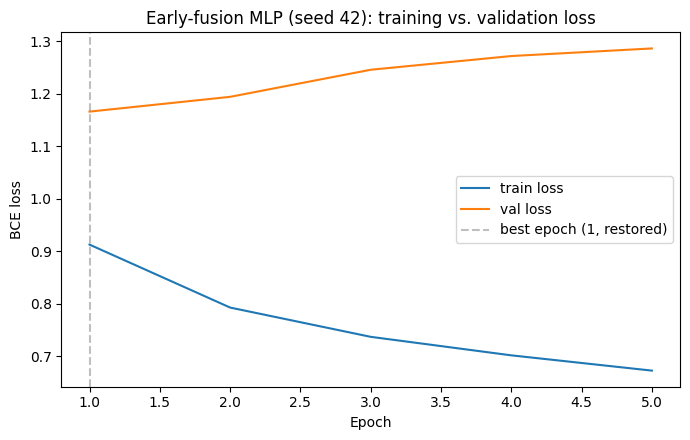

In [ ]:
mlp_runs = []
for seed in SEEDS:
    t0 = time.time()
    model, history, best_val_loss = train_early_fusion_mlp(
        mlp_train_loader, mlp_val_loader, DEVICE,
        num_negatives=MLP_NUM_NEGATIVES, lr=1e-3, weight_decay=1e-4,
        max_epochs=20, patience=4, seed=seed, verbose=False)
    train_time = time.time() - t0

    train_m, _ = timed_early_fusion_eval(model, "train", max_screens=MAX_TRAIN_EVAL_SCREENS)
    val_m, _ = timed_early_fusion_eval(model, "val")
    test_m, test_scores = timed_early_fusion_eval(model, "test")

    print(f"MLP seed={seed}: {len(history['train_loss'])} epochs ({train_time:.1f}s) -- "
          f"test R@10 image->text={test_m['R@10 image->text']:.4f}, "
          f"text->image={test_m['R@10 text->image']:.4f}")
    mlp_runs.append({"seed": seed, "model": model, "history": history, "train_time": train_time,
                     "train_metrics": train_m, "val_metrics": val_m, "test_metrics": test_m,
                     "test_scores": test_scores})

mlp_model = mlp_runs[0]["model"]  # seed 42
print(f"\nEarlyFusionScorer: {count_parameters(mlp_model):,} trainable parameters "
      f"(same architecture every seed)")
plot_loss_curve(mlp_runs[0]["history"], "Early-fusion MLP (seed 42): training vs. validation loss",
                 "results/figures/fig5b_early_fusion_loss_curve_rerun.png", ylabel="BCE loss")
plt.show()


In [ ]:
mlp_train_metrics, mlp_train_std = aggregate_seed_metrics([r["train_metrics"] for r in mlp_runs])
mlp_val_metrics, mlp_val_std = aggregate_seed_metrics([r["val_metrics"] for r in mlp_runs])
mlp_test_metrics, mlp_test_std = aggregate_seed_metrics([r["test_metrics"] for r in mlp_runs])
mlp_train_time = float(np.mean([r["train_time"] for r in mlp_runs]))

print("Early fusion MLP -- mean across 3 seeds, train (2,000-screen sample):")
print(mlp_train_metrics)
print("\nEarly fusion MLP -- mean across 3 seeds, validation:"); print(mlp_val_metrics)
print("\nEarly fusion MLP -- mean across 3 seeds, test:"); print(mlp_test_metrics)
print("\nEarly fusion MLP -- std across 3 seeds, test (spread across runs, not a second model):")
print(mlp_test_std)


Early fusion MLP -- mean across 3 seeds, train (2,000-screen sample):
{'R@1 image->text': 0.009666666543732086, 'R@1 text->image': 0.005666666819403569, 'R@5 image->text': 0.04266666745146116, 'R@5 text->image': 0.030000000571211178, 'R@10 image->text': 0.07066666583220164, 'R@10 text->image': 0.05966666713356972, 'MRR image->text': 0.03448693578441938, 'MRR text->image': 0.02749336821337541, 'median_rank image->text': 201.66666666666666, 'median_rank text->image': 205.33333333333334, 'AUC': 0.8284190353510089, 'n_screens_scored': 2000.0, 'n_pairs_scored': 4000000.0, 'scoring_time_sec': 3.4933333333333336, 'ms_per_pair': 0.0009000000000000001}

Early fusion MLP -- mean across 3 seeds, validation:
{'R@1 image->text': 0.00592216569930315, 'R@1 text->image': 0.004512126247088115, 'R@5 image->text': 0.02834179438650608, 'R@5 text->image': 0.02298364353676637, 'R@10 image->text': 0.047800338516632714, 'R@10 text->image': 0.04399323215087255, 'MRR image->text': 0.024716975788275402, 'MRR tex

## Technique 3 — Contrastive dual encoder (retrained, 3 seeds)

Retrained at the temperature already selected in notebook 04 through the shared `train_dual_encoder`,
once per seed in `SEEDS`. Trains on the raw `data`, not
standardised, L2-normalising the projected embeddings is what is mattering here and not raw input scale.

In [ ]:
BATCH_SIZE_DUAL = 512
dual_train_loader = DataLoader(
    PairDataset(data["train"]["flat_df"], data["train"]["image_features"],
                data["train"]["flat_text_features"], screen_idx["train"]),
    batch_size=BATCH_SIZE_DUAL, shuffle=True, drop_last=True)
dual_val_loader = DataLoader(
    PairDataset(data["val"]["flat_df"], data["val"]["image_features"],
                data["val"]["flat_text_features"], screen_idx["val"]),
    batch_size=BATCH_SIZE_DUAL, shuffle=False, drop_last=True)


@torch.no_grad()
def dual_eval(image_proj, text_proj, split_name, max_screens=None):
    image_proj.eval(); text_proj.eval()
    d = data[split_name]
    sel = subsample_idx(d["image_features"].shape[0], max_screens, seed=0)
    img_feats = d["image_features"][sel].to(DEVICE)
    txt_feats = d["eval_text_features"][sel].to(DEVICE)

    t0 = time.time()
    img_emb = F.normalize(image_proj(img_feats), dim=1)
    txt_emb = F.normalize(text_proj(txt_feats), dim=1)
    scores = cosine_score_matrix(img_emb, txt_emb).cpu()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - t0

    report = retrieval_report(scores, ks=(1, 5, 10))
    n = scores.shape[0]
    report["n_screens_scored"] = n
    report["n_pairs_scored"] = n * n
    report["encode_plus_scoring_time_sec"] = round(elapsed, 4)
    report["us_per_pair"] = round(1e6 * elapsed / (n * n), 4)
    return report, scores, sel


Dual encoder seed=42: 6 epochs (30.9s) -- test R@10 image->text=0.0550, text->image=0.0575
Dual encoder seed=123: 5 epochs (25.3s) -- test R@10 image->text=0.0429, text->image=0.0415
Dual encoder seed=2024: 6 epochs (29.8s) -- test R@10 image->text=0.0599, text->image=0.0606

ImageProjector+TextProjector: 1,705,472 trainable parameters (same architecture every seed)


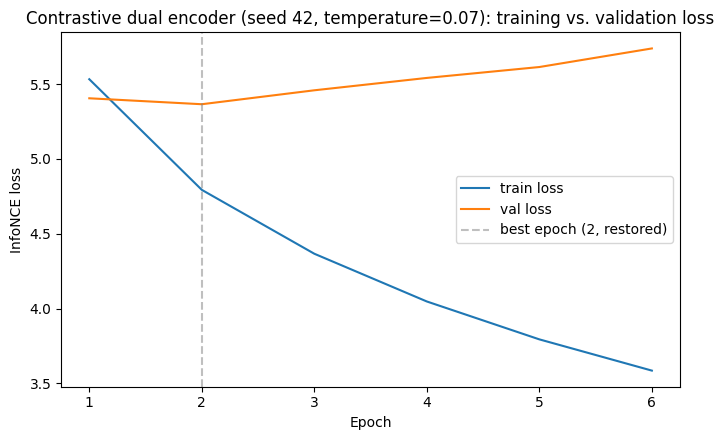

In [ ]:
dual_runs = []
for seed in SEEDS:
    t0 = time.time()
    img_proj_s, txt_proj_s, history, best_val_loss = train_dual_encoder(
        dual_train_loader, dual_val_loader, DEVICE,
        temperature=DUAL_TEMPERATURE, embed_dim=256, lr=1e-3, max_epochs=30, patience=4,
        seed=seed, verbose=False)
    train_time = time.time() - t0

    train_m, _, _ = dual_eval(img_proj_s, txt_proj_s, "train", max_screens=MAX_TRAIN_EVAL_SCREENS)
    val_m, _, _ = dual_eval(img_proj_s, txt_proj_s, "val")
    test_m, test_scores, test_sel = dual_eval(img_proj_s, txt_proj_s, "test")

    print(f"Dual encoder seed={seed}: {len(history['train_loss'])} epochs ({train_time:.1f}s) -- "
          f"test R@10 image->text={test_m['R@10 image->text']:.4f}, "
          f"text->image={test_m['R@10 text->image']:.4f}")
    dual_runs.append({"seed": seed, "image_proj": img_proj_s, "text_proj": txt_proj_s,
                       "history": history, "train_time": train_time,
                       "train_metrics": train_m, "val_metrics": val_m, "test_metrics": test_m,
                       "test_scores": test_scores, "test_sel": test_sel})

image_proj, text_proj = dual_runs[0]["image_proj"], dual_runs[0]["text_proj"]  # seed 42 is used from here on

print(f"\nImageProjector+TextProjector: "
      f"{count_parameters(image_proj) + count_parameters(text_proj):,} trainable parameters "
      f"(same architecture every seed)")
plot_loss_curve(dual_runs[0]["history"],
                 f"Contrastive dual encoder (seed 42, temperature={DUAL_TEMPERATURE}): "
                 "training vs. validation loss",
                 "results/figures/fig7b_contrastive_loss_curve_rerun.png", ylabel="InfoNCE loss")
plt.show()


In [ ]:
dual_train_metrics, dual_train_std = aggregate_seed_metrics([r["train_metrics"] for r in dual_runs])
dual_val_metrics, dual_val_std = aggregate_seed_metrics([r["val_metrics"] for r in dual_runs])
dual_test_metrics, dual_test_std = aggregate_seed_metrics([r["test_metrics"] for r in dual_runs])
dual_train_time = float(np.mean([r["train_time"] for r in dual_runs]))

# seed 42's score matrix and screen selection used for the failure-case/category sections below
dual_test_scores, dual_test_sel = dual_runs[0]["test_scores"], dual_runs[0]["test_sel"]

print("Dual encoder -- mean across 3 seeds, train (2,000-screen sample):"); print(dual_train_metrics)
print("\nDual encoder -- mean across 3 seeds, validation:"); print(dual_val_metrics)
print("\nDual encoder -- mean across 3 seeds, test:"); print(dual_test_metrics)
print("\nDual encoder -- std across 3 seeds, test (spread across runs, not a second model):")
print(dual_test_std)


Dual encoder -- mean across 3 seeds, train (2,000-screen sample):
{'R@1 image->text': 0.03833333340783914, 'R@1 text->image': 0.03549999992052714, 'R@5 image->text': 0.12333333243926366, 'R@5 text->image': 0.11999999980131786, 'R@10 image->text': 0.19050000111262003, 'R@10 text->image': 0.18650000294049582, 'MRR image->text': 0.0901527926325798, 'MRR text->image': 0.08717524756987889, 'median_rank image->text': 78.66666666666667, 'median_rank text->image': 80.0, 'AUC': 0.9005727206728364, 'n_screens_scored': 2000.0, 'n_pairs_scored': 4000000.0, 'encode_plus_scoring_time_sec': 0.010466666666666666, 'us_per_pair': 0.0026000000000000003}

Dual encoder -- mean across 3 seeds, validation:
{'R@1 image->text': 0.01692047342658043, 'R@1 text->image': 0.015933446275691193, 'R@5 image->text': 0.05640157808860143, 'R@5 text->image': 0.050902425001064934, 'R@10 image->text': 0.08728144566218059, 'R@10 text->image': 0.08699943621953328, 'MRR image->text': 0.04420517012476921, 'MRR text->image': 0.0

In [ ]:
# per-query cost against a precomputed candidate index
@torch.no_grad()
def single_query_cost(cached_text_emb, n_repeats=50):
    image_proj.eval()
    query_img = data["test"]["image_features"][:1].to(DEVICE)
    _ = cosine_score_matrix(F.normalize(image_proj(query_img), dim=1).cpu(), cached_text_emb)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n_repeats):
        q_emb = F.normalize(image_proj(query_img), dim=1).cpu()
        _ = cosine_score_matrix(q_emb, cached_text_emb)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t0) / n_repeats


with torch.no_grad():
    cached_test_text_emb = F.normalize(
        text_proj(data["test"]["eval_text_features"].to(DEVICE)), dim=1).cpu()

dual_ms_per_query = 1000 * single_query_cost(cached_test_text_emb)
print(f"Dual encoder per-query cost against a precomputed "
      f"{len(cached_test_text_emb)}-candidate index: {dual_ms_per_query:.4f} ms")


Dual encoder per-query cost against a precomputed 4310-candidate index: 1.2644 ms


## Comparing BERT pooling methods: mean vs. [CLS] token

In the proposal we said testing mean-pooling vs. the [CLS] token for BERT
sentence vectors, rather than just picking one from the literature (`extract_bert_features`'s
default). That is done here.
Refits Ridge on [CLS]-pooled features, using the same alphas already
selected under mean pooling and reused rather than re-tuned, so this stays a pooling comparison, not
a second alpha search. Compared on validation only as seen in our practical in class. Only Ridge is
re-run and the MLP and dual encoder aren't, since Ridge alone answers whether pooling matters.

In [ ]:
# load a fresh frozen BERT model
bert_cls, bert_tokenizer_cls = build_bert_backbone(DEVICE)

data_cls = {}
for split_name in ("train", "val"):
    d = data[split_name]
    cls_feats, cls_elapsed = extract_bert_features(
        d["flat_df"]["caption"].tolist(), bert_cls, bert_tokenizer_cls, DEVICE, pooling="cls")
    eval_mask = (d["flat_df"]["caption_idx"] == 0).values
    data_cls[split_name] = {
        "screenId": d["screenId"], "image_features": d["image_features"], "flat_df": d["flat_df"],
        "flat_text_features": cls_feats, "eval_df": d["eval_df"],
        "eval_text_features": cls_feats[eval_mask],
    }
    print(f"{split_name}: [CLS]-pooled BERT features extracted in {cls_elapsed:.1f}s "
          f"({len(d['flat_df'])} captions)")

del bert_cls, bert_tokenizer_cls
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT features (cls pooling):   0%|          | 0/615 [00:00<?, ?it/s]

train: [CLS]-pooled BERT features extracted in 59.9s (78715 captions)


BERT features (cls pooling):   0%|          | 0/93 [00:00<?, ?it/s]

val: [CLS]-pooled BERT features extracted in 9.2s (11820 captions)


In [ ]:
# the standardised copy made is used all this section needs from here on
data_cls_std = standardize_features(data_cls, splits=("train", "val"), fit_split="train")
del data_cls


def build_xy_cls(split_name):
    idx = data_cls_std[split_name]["flat_df"]["screenId"].map(
        lambda s: screen_idx[split_name][int(s)]).to_numpy()
    X_img = data_cls_std[split_name]["image_features"][idx].numpy()
    Y_txt = data_cls_std[split_name]["flat_text_features"].numpy()
    return X_img, Y_txt


X_img_train_cls, Y_txt_train_cls = build_xy_cls("train")
ridge_i2t_cls = Ridge(alpha=RIDGE_ALPHA_I2T).fit(X_img_train_cls, Y_txt_train_cls)
ridge_t2i_cls = Ridge(alpha=RIDGE_ALPHA_T2I).fit(Y_txt_train_cls, X_img_train_cls)

img_val_cls = data_cls_std["val"]["image_features"]
txt_val_cls = data_cls_std["val"]["eval_text_features"]
pred_txt_cls = torch.tensor(ridge_i2t_cls.predict(img_val_cls.numpy()), dtype=torch.float32)
scores_i2t_cls = cosine_score_matrix(pred_txt_cls, txt_val_cls)
pred_img_cls = torch.tensor(ridge_t2i_cls.predict(txt_val_cls.numpy()), dtype=torch.float32)
scores_t2i_cls = cosine_score_matrix(pred_img_cls, img_val_cls)

pooling_ablation_rows = [
    {"pooling": "mean (used throughout this project)",
     "val_R@10_image->text": ridge_val_metrics["R@10 image->text"],
     "val_R@10_text->image": ridge_val_metrics["R@10 text->image"]},
    {"pooling": "[CLS] token",
     "val_R@10_image->text": recall_at_k(scores_i2t_cls, 10),
     "val_R@10_text->image": recall_at_k(scores_t2i_cls, 10)},
]
pooling_ablation_df = pd.DataFrame(pooling_ablation_rows)
pooling_ablation_df.to_csv("results/tables/pooling_ablation.csv", index=False)
pooling_ablation_df


,pooling,val_R@10_image->text,val_R@10_text->image
0,mean (used throughout this project),0.052030,0.050338
1,[CLS] token,0.038071,0.041455


## Loading raw screenshots (for CLIP and the failure-case analysis)

Everything above uses cached ResNet-50/BERT features, never raw images. CLIP and the
failure-case analysis both need the actual screenshots, so they're loaded once
here and reused by both.

In [ ]:
from datasets import load_dataset

raw_test = load_dataset("rootsautomation/RICO-Screen2Words")["test"]
raw_screen_lookup = {sid: i for i, sid in enumerate(raw_test["screenId"])}
print(f"Raw test-split images loaded: {len(raw_test)} screens.")


Raw test-split images loaded: 4310 screens.


## CLIP zero-shot

This is just a reference point for the README's Key results table of how well does a big,
general-purpose pretrained vision-language model do on this task with zero adaptation. We
load `openai/clip-vit-base-patch32` as is and run it through the same
`cosine_score_matrix`/`retrieval_report` pipeline used everywhere else, so the Recall@K numbers
are directly comparable to our own techniques. We evaluate it on test only.

In [ ]:
from transformers import CLIPModel, CLIPProcessor

CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).eval().to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
clip_param_count = count_parameters(clip_model)  # saving now before clip_model gets freed below
print(f"CLIP ({CLIP_MODEL_NAME}): {clip_param_count:,} parameters "
      f"(frozen, zero-shot — not trained or fine-tuned here)")


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP (openai/clip-vit-base-patch32): 151,277,313 parameters (frozen, zero-shot — not trained or fine-tuned here)


In [ ]:
@torch.no_grad()
def clip_encode_screens(screen_ids, raw_ds, screen_lookup, batch_size=64, show_progress=True):
    # encodes CLIP image features one batch at a time, decoding images on demand
    feats = []
    rng = range(0, len(screen_ids), batch_size)
    if show_progress:
        rng = tqdm(rng, desc="CLIP image features")
    for start in rng:
        batch_ids = screen_ids[start:start + batch_size]
        batch_images = [raw_ds[screen_lookup[int(sid)]]["image"].convert("RGB") for sid in batch_ids]
        inputs = clip_processor(images=batch_images, return_tensors="pt").to(DEVICE)
        out = clip_model.get_image_features(**inputs)
        # get_image_features() returns a plain tensor and isinstance check below is just a fallback
        image_embeds = out if isinstance(out, torch.Tensor) else out.pooler_output
        feats.append(image_embeds.float().cpu())
    return torch.cat(feats, dim=0)


@torch.no_grad()
def clip_encode_texts(texts, batch_size=128, show_progress=True):
    feats = []
    rng = range(0, len(texts), batch_size)
    if show_progress:
        rng = tqdm(rng, desc="CLIP text features")
    for start in rng:
        batch = texts[start:start + batch_size]
        inputs = clip_processor(text=batch, return_tensors="pt", padding=True,
                                 truncation=True).to(DEVICE)
        out = clip_model.get_text_features(**inputs)
        text_embeds = out if isinstance(out, torch.Tensor) else out.pooler_output
        feats.append(text_embeds.float().cpu())
    return torch.cat(feats, dim=0)


# same eval set (full test split) used by every other technique here
clip_eval_df = data["test"]["eval_df"]
clip_screen_ids = clip_eval_df["screenId"].tolist()
clip_captions = clip_eval_df["caption"].tolist()

t0 = time.time()
clip_image_feats = clip_encode_screens(clip_screen_ids, raw_test, raw_screen_lookup)
clip_text_feats = clip_encode_texts(clip_captions)
clip_encode_time = time.time() - t0
print(f"CLIP zero-shot encoding time (test, {len(clip_screen_ids)} screens): "
      f"{clip_encode_time:.2f} sec")

CLIP image features:   0%|          | 0/68 [00:00<?, ?it/s]

CLIP text features:   0%|          | 0/34 [00:00<?, ?it/s]

CLIP zero-shot encoding time (test, 4310 screens): 307.82 sec


In [ ]:
clip_test_scores = cosine_score_matrix(clip_image_feats, clip_text_feats)
clip_test_metrics = retrieval_report(clip_test_scores, ks=(1, 5, 10))
clip_test_metrics["n_screens_scored"] = len(clip_screen_ids)
print("CLIP zero-shot — test:"); print(clip_test_metrics)

# Frees ~600MB, nothing below needs CLIP's weights again
del clip_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


CLIP zero-shot — test:
{'R@1 image->text': 0.05382830649614334, 'R@1 text->image': 0.05104408413171768, 'R@5 image->text': 0.1320185661315918, 'R@5 text->image': 0.11925753951072693, 'R@10 image->text': 0.1788863092660904, 'R@10 text->image': 0.16426913440227509, 'MRR image->text': 0.09798901528120041, 'MRR text->image': 0.09066137671470642, 'median_rank image->text': 174.0, 'median_rank text->image': 213.0, 'AUC': np.float64(0.8225480549049525), 'n_screens_scored': 4310}


## Final comparison table

All three trained techniques have same splits and train capped at 2000 screens for a fair comparison.
The random baseline and CLIP zero-shot are included as reference rows only and are not required
techniques. Random marks the floor and CLIP marks what a larger pretrained model does with no
RICO-specific training.

The MLP and dual-encoder rows are the mean across 3 seeds, `seed_std_R@10 ...` columns are the
std across those runs, and are exactly 0.0 for the deterministic ones that are random, Ridge, CLIP.
These are not unmeasured since those always give the identical result.

In [ ]:
def add_comparison_rows(rows, technique, metrics_by_split, std_by_split=None):
    for split_name, m in metrics_by_split:
        row = {"technique": technique, "split": split_name, **m}
        std = (std_by_split or {}).get(split_name)
        row["seed_std_R@10 image->text"] = std["R@10 image->text"] if std else 0.0
        row["seed_std_R@10 text->image"] = std["R@10 text->image"] if std else 0.0
        rows.append(row)


rows = []
add_comparison_rows(rows, "Random baseline (reference, no training)",
                     [("train_2000", random_train_metrics), ("val", random_val_metrics),
                      ("test", random_test_metrics)])
add_comparison_rows(rows, "Ridge regression (baseline)",
                     [("train_2000", ridge_train_metrics), ("val", ridge_val_metrics),
                      ("test", ridge_test_metrics)])
add_comparison_rows(rows, "Early fusion (MLP)",
                     [("train_2000", mlp_train_metrics), ("val", mlp_val_metrics),
                      ("test", mlp_test_metrics)],
                     {"train_2000": mlp_train_std, "val": mlp_val_std, "test": mlp_test_std})
add_comparison_rows(rows, "Contrastive dual encoder",
                     [("train_2000", dual_train_metrics), ("val", dual_val_metrics),
                      ("test", dual_test_metrics)],
                     {"train_2000": dual_train_std, "val": dual_val_std, "test": dual_test_std})
add_comparison_rows(rows, "CLIP zero-shot (reference, no training)", [("test", clip_test_metrics)])

final_comparison_df = pd.DataFrame(rows)
final_comparison_df.to_csv("results/tables/final_comparison.csv", index=False)
final_comparison_df


,technique,split,R@1 image->text,R@1 text->image,R@5 image->text,R@5 text->image,R@10 image->text,R@10 text->image,MRR image->text,MRR text->image,...,seed_std_R@10 image->text,seed_std_R@10 text->image,AUC image->text,AUC text->image,n_screens_scored,n_pairs_scored,scoring_time_sec,ms_per_pair,encode_plus_scoring_time_sec,us_per_pair
0,"Random baseline (reference, no training)",train_2000,0.000000,0.000500,0.001500,0.003000,0.003500,0.005000,0.003298,0.003895,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Random baseline (reference, no training)",val,0.000000,0.000000,0.000846,0.001269,0.004230,0.003384,0.003029,0.003009,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Random baseline (reference, no training)",test,0.000464,0.000000,0.000928,0.001160,0.001624,0.001856,0.002078,0.001948,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ridge regression (baseline),train_2000,0.061000,0.035500,0.123500,0.092000,0.172000,0.132500,0.098592,0.069236,...,0.000000,0.000000,0.828878,0.773424,2000.0,NaN,NaN,NaN,NaN,NaN
4,Ridge regression (baseline),val,0.008037,0.009306,0.032149,0.032149,0.052030,0.050338,0.025598,0.026537,...,0.000000,0.000000,0.722101,0.716148,2364.0,NaN,NaN,NaN,NaN,NaN
5,Ridge regression (baseline),test,0.005568,0.006497,0.019954,0.024362,0.032947,0.038515,0.016782,0.019937,...,0.000000,0.000000,0.722785,0.710851,4310.0,NaN,NaN,NaN,NaN,NaN
6,Early fusion (MLP),train_2000,0.009667,0.005667,0.042667,0.030000,0.070667,0.059667,0.034487,0.027493,...,0.002718,0.006637,NaN,NaN,2000.0,4000000.0,3.493333,0.000900,NaN,NaN
7,Early fusion (MLP),val,0.005922,0.004512,0.028342,0.022984,0.047800,0.043993,0.024717,0.021662,...,0.001245,0.003070,NaN,NaN,2364.0,5588496.0,4.816667,0.000867,NaN,NaN
8,Early fusion (MLP),test,0.003480,0.004099,0.016473,0.015081,0.029544,0.028152,0.015526,0.015542,...,0.001043,0.000972,NaN,NaN,4310.0,18576100.0,16.273333,0.000900,NaN,NaN
9,Contrastive dual encoder,train_2000,0.038333,0.035500,0.123333,0.120000,0.190500,0.186500,0.090153,0.087175,...,0.046352,0.047782,NaN,NaN,2000.0,4000000.0,NaN,NaN,0.010467,0.002600


### Seed variance detail (MLP and dual encoder, per seed)

The table above collapses the 3 seeds into mean ± std and this keeps each run's test result too. So
we can see the actual spread rather than just one std number which is useful for checking whether a
single lucky or unlucky run is skewing the result.

In [ ]:
seed_detail_rows = []
for r in mlp_runs:
    seed_detail_rows.append({"technique": "Early fusion (MLP)", "seed": r["seed"],
                              "train_time_sec": round(r["train_time"], 2),
                              **{f"test_{k}": v for k, v in r["test_metrics"].items()}})
for r in dual_runs:
    seed_detail_rows.append({"technique": "Contrastive dual encoder", "seed": r["seed"],
                              "train_time_sec": round(r["train_time"], 2),
                              **{f"test_{k}": v for k, v in r["test_metrics"].items()}})

seed_detail_df = pd.DataFrame(seed_detail_rows)
seed_detail_df.to_csv("results/tables/seed_variance_detail.csv", index=False)
seed_detail_df[["technique", "seed", "train_time_sec", "test_R@10 image->text",
                "test_R@10 text->image", "test_MRR image->text", "test_MRR text->image"]]


,technique,seed,train_time_sec,test_R@10 image->text,test_R@10 text->image,test_MRR image->text,test_MRR text->image
0,Early fusion (MLP),42,30.75,0.029466,0.027842,0.015353,0.015016
1,Early fusion (MLP),123,30.58,0.028306,0.029466,0.015444,0.015597
2,Early fusion (MLP),2024,29.93,0.030858,0.027146,0.015781,0.016013
3,Contrastive dual encoder,42,30.90,0.054988,0.057541,0.026697,0.029418
4,Contrastive dual encoder,123,25.25,0.042923,0.041531,0.022049,0.022089
5,Contrastive dual encoder,2024,29.79,0.059861,0.060557,0.027352,0.028880


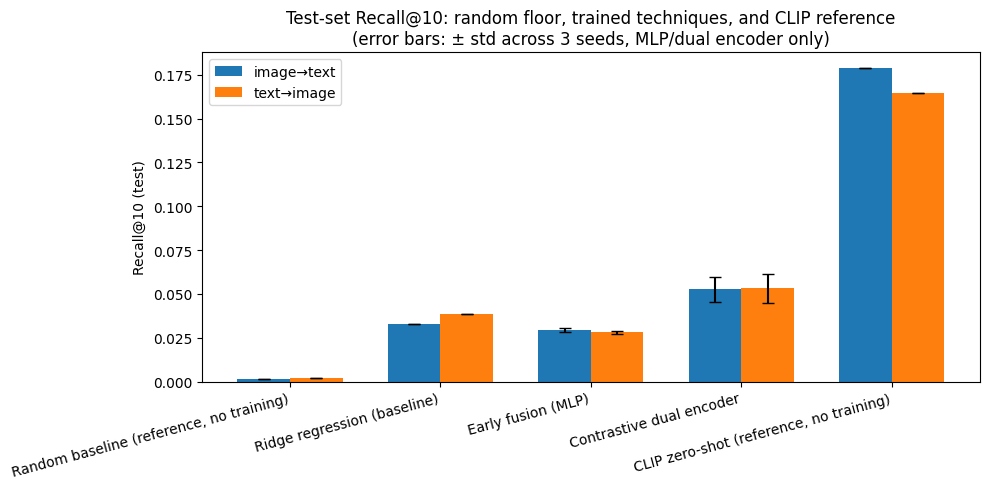

In [ ]:
# grouped bar chart of test R@10 (both directions) for every row in the comparison table also with error bars (±std) for the MLP/dual encoder
test_rows = final_comparison_df[final_comparison_df["split"] == "test"]
techniques = test_rows["technique"].tolist()
r10_i2t = test_rows["R@10 image->text"].tolist()
r10_t2i = test_rows["R@10 text->image"].tolist()
err_i2t = test_rows["seed_std_R@10 image->text"].tolist()
err_t2i = test_rows["seed_std_R@10 text->image"].tolist()

x = np.arange(len(techniques))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width / 2, r10_i2t, width, yerr=err_i2t, capsize=4, label="image→text")
ax.bar(x + width / 2, r10_t2i, width, yerr=err_t2i, capsize=4, label="text→image")
ax.set_xticks(x); ax.set_xticklabels(techniques, rotation=15, ha="right")
ax.set_ylabel("Recall@10 (test)")
ax.set_title("Test-set Recall@10: random floor, trained techniques, and CLIP reference\n"
             "(error bars: ± std across 3 seeds, MLP/dual encoder only)")
ax.legend()
fig.tight_layout()
fig.savefig("results/figures/fig9_recall_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## Overfitting check

Train 2000-screen sample vs validation vs test Recall@10. A meaningfully higher train score than
val/test would indicate memorisation rather than a genuinely learned cross-modal mapping.

In [ ]:
overfit_rows = []
for technique, (tr, va, te) in [
    ("Ridge regression (baseline)", (ridge_train_metrics, ridge_val_metrics, ridge_test_metrics)),
    ("Early fusion (MLP)", (mlp_train_metrics, mlp_val_metrics, mlp_test_metrics)),
    ("Contrastive dual encoder", (dual_train_metrics, dual_val_metrics, dual_test_metrics)),
]:
    overfit_rows.append({
        "technique": technique,
        "train_R@10_i2t (2000-screen sample)": tr["R@10 image->text"],
        "val_R@10_i2t": va["R@10 image->text"],
        "test_R@10_i2t": te["R@10 image->text"],
        "train_minus_test_gap_i2t": tr["R@10 image->text"] - te["R@10 image->text"],
    })

overfit_df = pd.DataFrame(overfit_rows)
overfit_df


,technique,train_R@10_i2t (2000-screen sample),val_R@10_i2t,test_R@10_i2t,train_minus_test_gap_i2t
0,Ridge regression (baseline),0.172000,0.052030,0.032947,0.139053
1,Early fusion (MLP),0.070667,0.047800,0.029544,0.041123
2,Contrastive dual encoder,0.190500,0.087281,0.052591,0.137909


## Efficiency comparison

This pulls training time, parameter count, and per-query cost into one table. Ridge is a
closed-form map, so it's basically instant per query. The MLP has to re-run its network once per
candidate, so `ms_per_pair` grows with the candidate set size. The dual encoder just encodes the
query once and does a single matrix-vector multiply against a precomputed index. That per-query
gap is the project's main efficiency finding.

Just note that for the MLP and dual encoder, `train_time_sec` is the mean time per run across the 3
seeds, so it stays comparable to Ridge/CLIP's single-run time. The real wall-clock cost is about
3x that, `train_time_sec_total_3_seeds` gives that number directly.

In [ ]:
# the full test split
n_candidates = dual_test_scores.shape[1]

ridge_params = X_img_train.shape[1] * Y_txt_train.shape[1] * 2  # two linear models each 2048x768

efficiency_rows = [
    {"technique": "Ridge regression (baseline)",
     "trainable_parameters": ridge_params,
     "train_time_sec": round(ridge_train_time, 2),
     "train_time_sec_total_3_seeds": None,  # deterministic so no seed to total
     "per_query_cost": "closed-form linear predict + one cosine similarity pass (effectively instant)",
     "per_query_cost_ms": None,
     "scales_with_candidates": "no (one matrix multiply against all candidates at once)"},
    {"technique": "Early fusion (MLP)",
     "trainable_parameters": count_parameters(mlp_model),
     "train_time_sec": round(mlp_train_time, 2),  # average time per run across the 3 seeds
     "train_time_sec_total_3_seeds": round(sum(r["train_time"] for r in mlp_runs), 2),
     "per_query_cost": f"{mlp_test_metrics['ms_per_pair']:.4f} ms/pair x {n_candidates} candidates",
     "per_query_cost_ms": round(mlp_test_metrics["ms_per_pair"] * n_candidates, 2),
     "scales_with_candidates": "yes — linearly (must re-score every candidate pair)"},
    {"technique": "Contrastive dual encoder",
     "trainable_parameters": count_parameters(image_proj) + count_parameters(text_proj),
     "train_time_sec": round(dual_train_time, 2),  # average time per run across the 3 seeds
     "train_time_sec_total_3_seeds": round(sum(r["train_time"] for r in dual_runs), 2),
     "per_query_cost": "one encode + one matmul against a precomputed index",
     "per_query_cost_ms": round(dual_ms_per_query, 4),
     "scales_with_candidates": "no (one encode + one matmul against a precomputed index)"},
    {"technique": "CLIP zero-shot (reference, no training)",
     "trainable_parameters": clip_param_count,
     "train_time_sec": 0.0,  # zero-shot so no training
     "train_time_sec_total_3_seeds": None,  # deterministic so no seed to total
     "per_query_cost": "one CLIP encode + one matmul against a precomputed index "
                        "(full CLIP forward pass is heavier per-call than the small projector "
                        "heads above, but still O(1) in the candidate-set size)",
     "per_query_cost_ms": None,  # not timed separately as already counted in clip_encode_time above
     "scales_with_candidates": "no (one encode + one matmul against a precomputed index)"},
]
efficiency_df = pd.DataFrame(efficiency_rows)
efficiency_df.to_csv("results/tables/efficiency_comparison.csv", index=False)
efficiency_df

,technique,trainable_parameters,train_time_sec,train_time_sec_total_3_seeds,per_query_cost,per_query_cost_ms,scales_with_candidates
0,Ridge regression (baseline),3145728,11.61,NaN,closed-form linear predict + one cosine simila...,NaN,no (one matrix multiply against all candidates...
1,Early fusion (MLP),1508097,30.42,91.27,0.0009 ms/pair x 4310 candidates,3.8800,yes — linearly (must re-score every candidate ...
2,Contrastive dual encoder,1705472,28.65,85.94,one encode + one matmul against a precomputed ...,1.2644,no (one encode + one matmul against a precompu...
3,"CLIP zero-shot (reference, no training)",151277313,0.00,NaN,one CLIP encode + one matmul against a precomp...,NaN,no (one encode + one matmul against a precompu...


## Failure-case analysis

Specific test screens where the dual encoder which is the best-performing technique on the comparison
table above fails to retrieve the correct caption in its top 10, with the screenshot and true
vs predicted captions from all three techniques shown side by side. Uses the seed-42 dual
encoder (`dual_test_scores`), a per-screen investigation needs one concrete model, not an
average of three.

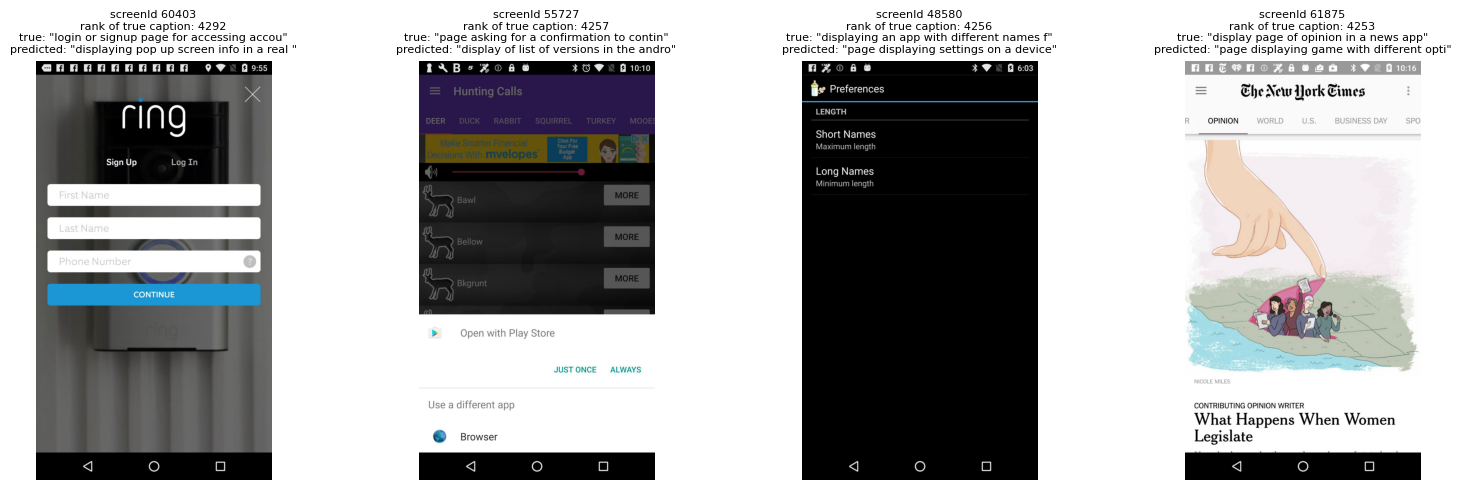

In [ ]:
# ranks the correct caption for each screen using the dual encoder's seed-42 scores
ranks = rank_of_correct(dual_test_scores)
worst_local_idx = torch.argsort(ranks, descending=True)[:4].tolist()

test_eval_df = data["test"]["eval_df"].iloc[dual_test_sel.tolist()].reset_index(drop=True)

# reusing raw_test/raw_screen_lookup from the CLIP section above

fig, axes = plt.subplots(1, len(worst_local_idx), figsize=(4 * len(worst_local_idx), 5))
for ax, local_i in zip(axes, worst_local_idx):
    screen_id = int(test_eval_df.iloc[local_i]["screenId"])
    true_caption = test_eval_df.iloc[local_i]["caption"]
    img = raw_test[raw_screen_lookup[screen_id]]["image"]

    top_pred_idx = int(torch.argmax(dual_test_scores[local_i]))
    pred_caption = test_eval_df.iloc[top_pred_idx]["caption"]

    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"screenId {screen_id}\nrank of true caption: {int(ranks[local_i])}\n"
                 f"true: \"{true_caption[:40]}\"\npredicted: \"{pred_caption[:40]}\"",
                 fontsize=8)

fig.tight_layout()
fig.savefig("results/figures/fig10_failure_cases.png", dpi=150, bbox_inches="tight")
plt.show()

## Per-app-category performance breakdown (ethics / fairness)

This checks whether the dataset's category imbalance actually shows up as a fairness gap in
retrieval quality. It just reuses
the `ranks` we already computed above, so no new training needed.

In [ ]:
category_df = test_eval_df.copy()
category_df["rank"] = ranks.tolist()
category_df["correct_in_top10"] = category_df["rank"] < 10

category_breakdown = (
    category_df.groupby("category")
    .agg(n_screens=("screenId", "count"), recall_at_10=("correct_in_top10", "mean"))
    .sort_values("n_screens", ascending=False)
    .reset_index()
)
category_breakdown.to_csv("results/tables/category_breakdown.csv", index=False)
category_breakdown


,category,n_screens,recall_at_10
0,Social,333,0.045045
1,Travel & Local,325,0.055385
2,Entertainment,313,0.060703
3,Communication,292,0.037671
4,Lifestyle,269,0.078067
5,Shopping,243,0.069959
6,Sports,242,0.074380
7,Education,233,0.034335
8,Health & Fitness,230,0.052174
9,Finance,189,0.026455


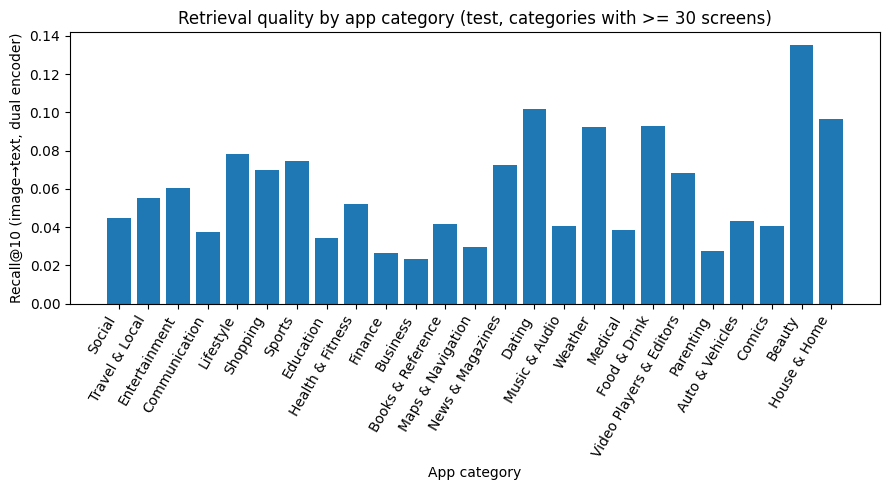

Categories excluded from the plot for having fewer than 30 screens in this test sample (see the full table above for their raw numbers):
['Art & Design', 'Events']


In [ ]:
# skip categories with too few screens to give a stable recall estimate
MIN_SCREENS_TO_PLOT = 30
plot_df = category_breakdown[category_breakdown["n_screens"] >= MIN_SCREENS_TO_PLOT]

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(plot_df["category"], plot_df["recall_at_10"])
ax.set_ylabel("Recall@10 (image→text, dual encoder)")
ax.set_xlabel("App category")
ax.set_title(f"Retrieval quality by app category (test, categories with "
             f">= {MIN_SCREENS_TO_PLOT} screens)")
plt.xticks(rotation=60, ha="right")
fig.tight_layout()
fig.savefig("results/figures/fig11_category_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Categories excluded from the plot for having fewer than {MIN_SCREENS_TO_PLOT} screens "
      f"in this test sample (see the full table above for their raw numbers):")
print(category_breakdown[category_breakdown["n_screens"] < MIN_SCREENS_TO_PLOT]["category"].tolist())
